# _**Project of Comp9444**_
**_Named Entity Recognition (NER) for Biomedical Texts using Large Language Models (LLMs)_**

这里需要写一下整个项目的结构（目录）：this notebook contain ......

## **_1. Introduction and Library Imports_**

这里需要说明问题的定义，包括研究的背景和动机，以及需要解决的问题

最后单独介绍一下引用的库（可以不做）


In [1]:
# import all the libs here
import numpy as np
import pandas as pd
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import shutil

print('all the libs are successfully imported')

all the libs are successfully imported


## **_2. Data Loading_**

这里需要说明数据来源，然后解释一下因为数据源下载格式是zip 文件，没办法直接下载到内存里进行操作，只能借助外部文件夹

还需要介绍一下，数据是三个txt文件，数据源已经分好了训练测试和验证

这个目前只适用于windows版本，MAC/Linux可能有问题

In [5]:
# from one of its subdirectories.
notebook_name = "MedNLP_research.ipynb"
notebook_dir = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / notebook_name).is_file()),
    Path.cwd(),
)
raw_data_dir = notebook_dir / "Dataset" / "RawData"
raw_data_dir.mkdir(parents=True, exist_ok=True)

# download for data scource
datasets = {
    "training": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBItrainset_corpus.zip",
        "source_name": "NCBItrainset_corpus.txt",
        "target_name": "NCBI_training.txt",
    },
    "validation": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBIdevelopset_corpus.zip",
        "source_name": "NCBIdevelopset_corpus.txt",
        "target_name": "NCBI_validation.txt",
    },
    "testing": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBItestset_corpus.zip",
        "source_name": "NCBItestset_corpus.txt",
        "target_name": "NCBI_testing.txt",
    },
}

for split, dataset_info in datasets.items():
    target_path = raw_data_dir / dataset_info["target_name"]

    if target_path.is_file():
        print(f"{split.capitalize()} set already exists: {target_path}")
        continue

    archive_path = raw_data_dir / Path(dataset_info["url"]).name
    partial_archive_path = archive_path.with_suffix(archive_path.suffix + ".part")
    partial_target_path = target_path.with_suffix(target_path.suffix + ".part")

    print(f"Downloading {split} set...")
    urlretrieve(dataset_info["url"], partial_archive_path)
    partial_archive_path.replace(archive_path)

    # decompress the file
    try:
        with ZipFile(archive_path) as zip_file:
            source_member = next(
                member for member in zip_file.namelist()
                if Path(member).name == dataset_info["source_name"]
            )
            with zip_file.open(source_member) as source, partial_target_path.open("wb") as target:
                shutil.copyfileobj(source, target)
        partial_target_path.replace(target_path)
    finally:
        archive_path.unlink(missing_ok=True)
        partial_target_path.unlink(missing_ok=True)

    print(f"Saved {split} set to: {target_path}")

print("NCBI Disease Corpus download and extraction completed.")

Saved training set to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\RawData\NCBI_training.txt
Saved validation set to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\RawData\NCBI_validation.txt
Saved testing set to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\RawData\NCBI_testing.txt
NCBI Disease Corpus download and extraction completed.


## **_3. Data Processing and Analysis_**

这里要说明处理的流程：

### 3.0 基础处理


In [2]:
import json
from pathlib import Path

# Locate the dataset directories from the project root.
project_dir = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "Dataset" / "RawData").is_dir()),
    Path.cwd(),
)
raw_data_dir = project_dir / "Dataset" / "RawData"
processed_data_dir = project_dir / "Dataset" / "ProcessedData"
processed_data_dir.mkdir(parents=True, exist_ok=True)

source_files = (
    "NCBI_training.txt",
    "NCBI_validation.txt",
    "NCBI_testing.txt",
)


def convert_pubtator_to_jsonl(input_path, output_path):
    # Keep every source block, including repeated PMIDs.
    documents = []
    document = None

    with input_path.open(encoding="utf-8") as source:
        for raw_line in source:
            line = raw_line.rstrip("\r\n")
            if not line:
                if document is not None:
                    documents.append(document)
                    document = None
                continue

            if "|t|" in line or "|a|" in line:
                pmid, section, content = line.split("|", 2)
                if section == "t":
                    document = {"pmid": pmid, "title": content, "abstract": "", "entities": []}
                else:
                    document["abstract"] = content
            else:
                fields = line.split("\t")
                pmid, start, end, mention = fields[:4]
                document["entities"].append(
                    {"start": int(start), "end": int(end), "mention": mention}
                )

    if document is not None:
        documents.append(document)

    mismatch_count = 0
    with output_path.open("w", encoding="utf-8") as destination:
        for document_index, document in enumerate(documents):
            # Corpus offsets use: title + one space + abstract.
            text = document["title"] + " " + document["abstract"]
            entities = []

            for entity in document["entities"]:
                start, end = entity["start"], entity["end"]
                if not 0 <= start < end <= len(text):
                    raise ValueError(
                        f"Invalid offset in PMID {document['pmid']}: [{start}, {end})"
                    )
                if text[start:end] != entity["mention"]:
                    mismatch_count += 1
                entities.append({"start": start, "end": end})

            record = {
                "record_id": f"{input_path.stem}-{document_index:04d}",
                "pmid": document["pmid"],
                "title": document["title"],
                "abstract": document["abstract"],
                "text": text,
                "entities": entities,
            }
            destination.write(json.dumps(record, ensure_ascii=False) + "\n")

    return len(documents), mismatch_count


for source_name in source_files:
    input_path = raw_data_dir / source_name
    output_path = processed_data_dir / Path(source_name).with_suffix(".jsonl").name
    document_count, mismatch_count = convert_pubtator_to_jsonl(input_path, output_path)
    print(
        f"Saved {document_count} documents to: {output_path} "
        f"({mismatch_count} annotation text mismatch(es))"
    )

Saved 593 documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\ProcessedData\NCBI_training.jsonl (1 annotation text mismatch(es))
Saved 100 documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\ProcessedData\NCBI_validation.jsonl (0 annotation text mismatch(es))
Saved 100 documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\ProcessedData\NCBI_testing.jsonl (0 annotation text mismatch(es))


数据完成基础清洗之后，接下来进行初步数据分析

### 3.1 数据规模与文档长度


,Documents,Unique PMIDs,Repeated Records,Entity Mentions,Unique Entity Texts,Mean Document Length,Median Document Length,95th Percentile Length,Maximum Document Length
Split,,,,,,,,,
Training,593,592,1,5145,1691,1264.72,1276.0,1909.80,2656
Validation,100,100,0,787,363,1326.40,1272.0,1895.40,2193
Testing,100,100,0,960,424,1352.84,1310.5,2007.05,2838


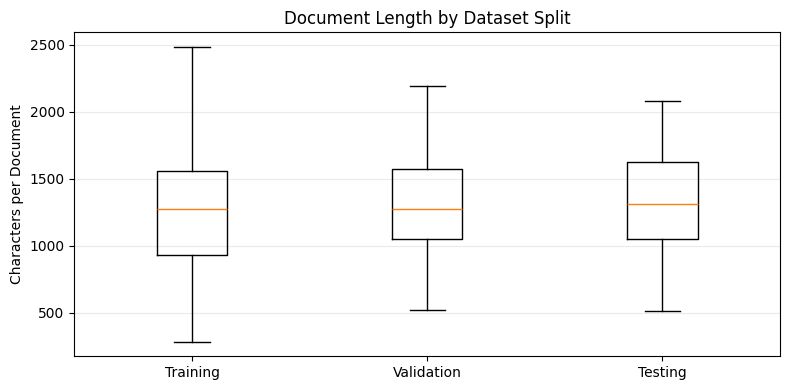

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display

# Load the processed documents for all official splits.
split_files = {
    "Training": "NCBI_training.jsonl",
    "Validation": "NCBI_validation.jsonl",
    "Testing": "NCBI_testing.jsonl",
}
records_by_split = {}

for split, file_name in split_files.items():
    file_path = processed_data_dir / file_name
    with file_path.open(encoding="utf-8") as source:
        records_by_split[split] = [json.loads(line) for line in source if line.strip()]

# Summarise dataset size and document character lengths.
scale_rows = []
for split, records in records_by_split.items():
    document_lengths = pd.Series([len(record["text"]) for record in records])
    entity_texts = [
        record["text"][entity["start"]:entity["end"]]
        for record in records
        for entity in record["entities"]
    ]
    unique_pmids = len({record["pmid"] for record in records})

    scale_rows.append({
        "Split": split,
        "Documents": len(records),
        "Unique PMIDs": unique_pmids,
        "Repeated Records": len(records) - unique_pmids,
        "Entity Mentions": len(entity_texts),
        "Unique Entity Texts": len(set(entity_texts)),
        "Mean Document Length": document_lengths.mean(),
        "Median Document Length": document_lengths.median(),
        "95th Percentile Length": document_lengths.quantile(0.95),
        "Maximum Document Length": document_lengths.max(),
    })

scale_summary = pd.DataFrame(scale_rows).set_index("Split")
display(scale_summary.round(2))

# Compare document-length distributions across splits.
plt.figure(figsize=(8, 4))
plt.boxplot(
    [[len(record["text"]) for record in records_by_split[split]] for split in split_files],
    tick_labels=list(split_files),
    showfliers=False,
)
plt.title("Document Length by Dataset Split")
plt.ylabel("Characters per Document")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 3.2 实体分布

,Entities per Document,"Entities per 1,000 Characters",Zero-Entity Documents,Mean Entity Length,Median Entity Length,95th Percentile Entity Length,Maximum Entity Length,Single-Word Entities (%),Multi-Word Entities (%)
Split,,,,,,,,,
Training,8.68,6.86,0,15.19,14.0,37.0,80,46.69,53.31
Validation,7.87,5.93,0,15.74,15.0,37.0,74,42.69,57.31
Testing,9.60,7.10,0,14.48,13.0,37.0,64,49.17,50.83


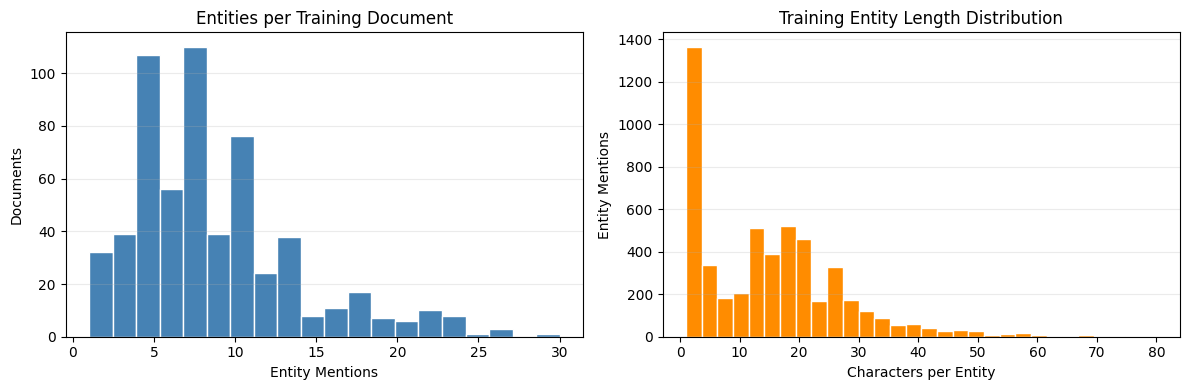

In [4]:
# Summarise entity density and character length for each split.
entity_rows = []
for split, records in records_by_split.items():
    entity_counts = pd.Series([len(record["entities"]) for record in records])
    entity_texts = [
        record["text"][entity["start"]:entity["end"]]
        for record in records
        for entity in record["entities"]
    ]
    entity_lengths = pd.Series([len(text) for text in entity_texts])
    total_characters = sum(len(record["text"]) for record in records)
    single_word_count = sum(len(text.split()) == 1 for text in entity_texts)

    entity_rows.append({
        "Split": split,
        "Entities per Document": entity_counts.mean(),
        "Entities per 1,000 Characters": len(entity_texts) / total_characters * 1000,
        "Zero-Entity Documents": int((entity_counts == 0).sum()),
        "Mean Entity Length": entity_lengths.mean(),
        "Median Entity Length": entity_lengths.median(),
        "95th Percentile Entity Length": entity_lengths.quantile(0.95),
        "Maximum Entity Length": entity_lengths.max(),
        "Single-Word Entities (%)": single_word_count / len(entity_texts) * 100,
        "Multi-Word Entities (%)": (len(entity_texts) - single_word_count) / len(entity_texts) * 100,
    })

entity_summary = pd.DataFrame(entity_rows).set_index("Split")
display(entity_summary.round(2))

# Plot the main entity distributions in the training set.
training_records = records_by_split["Training"]
training_entity_counts = [len(record["entities"]) for record in training_records]
training_entity_lengths = [
    entity["end"] - entity["start"]
    for record in training_records
    for entity in record["entities"]
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(training_entity_counts, bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Entities per Training Document")
axes[0].set_xlabel("Entity Mentions")
axes[0].set_ylabel("Documents")

axes[1].hist(training_entity_lengths, bins=30, color="darkorange", edgecolor="white")
axes[1].set_title("Training Entity Length Distribution")
axes[1].set_xlabel("Characters per Entity")
axes[1].set_ylabel("Entity Mentions")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### 3.3 tokenized by two methods
#### 3.3.1 BioBERT

In [6]:
from transformers.models.bert.tokenization_bert import BertTokenizerFast

BIOBERT_MODEL = "dmis-lab/biobert-base-cased-v1.1"
# BioBERT v1.1 inherits the BERT-base-cased WordPiece vocabulary.

BIOBERT_TOKENIZER = "google-bert/bert-base-cased"

training_path = processed_data_dir / "NCBI_training.jsonl"

biobert_output_dir = (
    project_dir / "Dataset" / "TokenizedData" / "BioBERT"
)
biobert_output_dir.mkdir(parents=True, exist_ok=True)

tokenized_training_path = (
    biobert_output_dir / "NCBI_training.jsonl"
)


def tokenize_training_data(
    input_path,
    output_path,
    tokenizer,
    model_name,
    tokenizer_name,
):
    document_count = 0
    token_count = 0

    with input_path.open(encoding="utf-8") as source:
        with output_path.open("w", encoding="utf-8") as destination:
            for line in source:
                if not line.strip():
                    continue

                record = json.loads(line)
                encoded = tokenizer(
                    record["text"],
                    add_special_tokens=False,
                    truncation=False,
                    return_attention_mask=True,
                    return_offsets_mapping=True,
                )
                tokens = tokenizer.convert_ids_to_tokens(
                    encoded["input_ids"]
                )
                offsets = [
                    {"start": start, "end": end}
                    for start, end in encoded["offset_mapping"]
                ]

                sequence_lengths = (
                    len(tokens),
                    len(encoded["input_ids"]),
                    len(encoded["attention_mask"]),
                    len(offsets),
                )
                if len(set(sequence_lengths)) != 1:
                    raise ValueError(
                        f"Token alignment failed for {record['record_id']}"
                    )

                has_invalid_offset = any(
                    not 0 <= offset["start"] < offset["end"]
                    <= len(record["text"])
                    for offset in offsets
                )
                if has_invalid_offset:
                    raise ValueError(
                        f"Invalid token offset in {record['record_id']}"
                    )

                tokenized_record = {
                    "record_id": record["record_id"],
                    "pmid": record["pmid"],
                    "model": model_name,
                    "tokenizer": tokenizer_name,
                    "text": record["text"],
                    "entities": record["entities"],
                    "tokens": tokens,
                    "input_ids": encoded["input_ids"],
                    "attention_mask": encoded["attention_mask"],
                    "offset_mapping": offsets,
                }
                destination.write(
                    json.dumps(tokenized_record, ensure_ascii=False)
                    + "\n"
                )
                document_count += 1
                token_count += len(tokens)

    return document_count, token_count


# A fast tokenizer is required to return character offsets.
biobert_tokenizer = BertTokenizerFast.from_pretrained(
    BIOBERT_TOKENIZER
)
if not biobert_tokenizer.is_fast:
    raise RuntimeError(
        "BioBERT fast tokenizer is required for offset mapping."
    )

document_count, token_count = tokenize_training_data(
    training_path,
    tokenized_training_path,
    biobert_tokenizer,
    BIOBERT_MODEL,
    BIOBERT_TOKENIZER,
)

print(
    f"Saved {document_count} BioBERT-tokenized documents to: "
    f"{tokenized_training_path}"
)
print(f"Total WordPiece tokens: {token_count}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (762 > 512). Running this sequence through the model will result in indexing errors


Saved 593 BioBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\BioBERT\NCBI_training.jsonl
Total WordPiece tokens: 184552


#### 3.3.2 BioBERT 分词结果分析

,Count,Mean,Median,Minimum,95th Percentile,Maximum
Measurement,,,,,,
WordPieces per document,593,311.22,307.0,74,492.8,762
Characters per WordPiece,184552,3.45,3.0,1,9.0,16
WordPieces per entity,5145,4.76,4.0,1,11.0,33


,Content WordPiece Limit,Documents Exceeding Limit,Documents Exceeding Limit (%)
Model Max Length,,,
128,126,577,97.30
256,254,396,66.78
512,510,24,4.05


,Count,Percentage
Metric,,
Single-WordPiece entities,243,4.72
Multi-WordPiece entities,4902,95.28
Boundary-aligned entities,5143,99.96
Boundary-unaligned entities,2,0.04


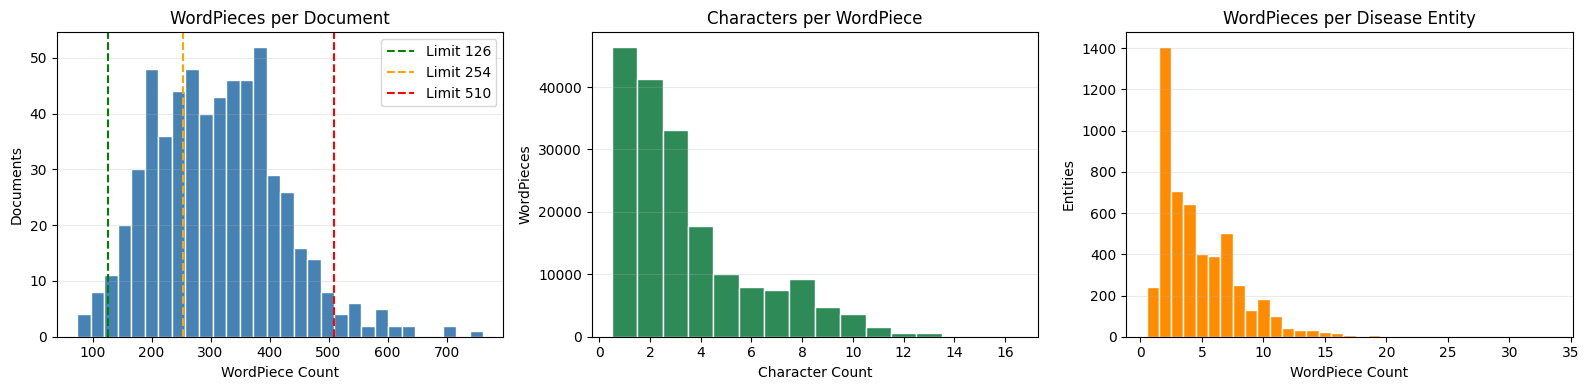

In [7]:
# Load the BioBERT-tokenized training records.
with tokenized_training_path.open(encoding="utf-8") as source:
    biobert_records = [
        json.loads(line) for line in source if line.strip()
    ]

document_token_counts = [
    len(record["tokens"]) for record in biobert_records
]
token_character_lengths = [
    offset["end"] - offset["start"]
    for record in biobert_records
    for offset in record["offset_mapping"]
]

entity_wordpiece_counts = []
boundary_aligned_entities = 0

for record in biobert_records:
    offsets = record["offset_mapping"]
    token_starts = {offset["start"] for offset in offsets}
    token_ends = {offset["end"] for offset in offsets}

    for entity in record["entities"]:
        wordpiece_count = sum(
            offset["start"] < entity["end"]
            and offset["end"] > entity["start"]
            for offset in offsets
        )
        entity_wordpiece_counts.append(wordpiece_count)

        is_boundary_aligned = (
            entity["start"] in token_starts
            and entity["end"] in token_ends
        )
        boundary_aligned_entities += int(is_boundary_aligned)


def describe_values(name, values):
    values = pd.Series(values)
    return {
        "Measurement": name,
        "Count": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Minimum": values.min(),
        "95th Percentile": values.quantile(0.95),
        "Maximum": values.max(),
    }


token_statistics = pd.DataFrame([
    describe_values("WordPieces per document", document_token_counts),
    describe_values("Characters per WordPiece", token_character_lengths),
    describe_values("WordPieces per entity", entity_wordpiece_counts),
]).set_index("Measurement")
display(token_statistics.round(2))

# Reserve two positions for [CLS] and [SEP].
capacity_rows = []
for model_max_length in (128, 256, 512):
    content_limit = model_max_length - 2
    exceeding_count = sum(
        count > content_limit for count in document_token_counts
    )
    capacity_rows.append({
        "Model Max Length": model_max_length,
        "Content WordPiece Limit": content_limit,
        "Documents Exceeding Limit": exceeding_count,
        "Documents Exceeding Limit (%)": (
            exceeding_count / len(document_token_counts) * 100
        ),
    })

capacity_summary = pd.DataFrame(capacity_rows).set_index(
    "Model Max Length"
)
display(capacity_summary.round(2))

total_entities = len(entity_wordpiece_counts)
single_wordpiece_entities = sum(
    count == 1 for count in entity_wordpiece_counts
)
entity_alignment_summary = pd.DataFrame({
    "Metric": [
        "Single-WordPiece entities",
        "Multi-WordPiece entities",
        "Boundary-aligned entities",
        "Boundary-unaligned entities",
    ],
    "Count": [
        single_wordpiece_entities,
        total_entities - single_wordpiece_entities,
        boundary_aligned_entities,
        total_entities - boundary_aligned_entities,
    ],
}).set_index("Metric")
entity_alignment_summary["Percentage"] = (
    entity_alignment_summary["Count"] / total_entities * 100
)
display(entity_alignment_summary.round(2))

# Plot document, token, and entity tokenization distributions.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(
    document_token_counts,
    bins=30,
    color="steelblue",
    edgecolor="white",
)
for limit, color in zip((126, 254, 510), ("green", "orange", "red")):
    axes[0].axvline(
        limit,
        color=color,
        linestyle="--",
        label=f"Limit {limit}",
    )
axes[0].set_title("WordPieces per Document")
axes[0].set_xlabel("WordPiece Count")
axes[0].set_ylabel("Documents")
axes[0].legend()

token_length_bins = np.arange(
    0.5, max(token_character_lengths) + 1.5, 1
)
axes[1].hist(
    token_character_lengths,
    bins=token_length_bins,
    color="seagreen",
    edgecolor="white",
)
axes[1].set_title("Characters per WordPiece")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("WordPieces")

entity_piece_bins = np.arange(
    0.5, max(entity_wordpiece_counts) + 1.5, 1
)
axes[2].hist(
    entity_wordpiece_counts,
    bins=entity_piece_bins,
    color="darkorange",
    edgecolor="white",
)
axes[2].set_title("WordPieces per Disease Entity")
axes[2].set_xlabel("WordPiece Count")
axes[2].set_ylabel("Entities")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

#### 3.3.3 PubMedBERT

In [9]:
from transformers.models.bert.tokenization_bert import BertTokenizerFast

PUBMEDBERT_MODEL = (
    "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"
)
training_path = processed_data_dir / "NCBI_training.jsonl"
pubmedbert_output_dir = (
    project_dir / "Dataset" / "TokenizedData" / "PubMedBERT"
)
pubmedbert_output_dir.mkdir(parents=True, exist_ok=True)
pubmedbert_training_path = (
    pubmedbert_output_dir / "NCBI_training.jsonl"
)


def tokenize_pubmedbert_training_data(input_path, output_path, tokenizer):
    document_count = 0
    token_count = 0

    with input_path.open(encoding="utf-8") as source:
        with output_path.open("w", encoding="utf-8") as destination:
            for line in source:
                if not line.strip():
                    continue

                record = json.loads(line)
                encoded = tokenizer(
                    record["text"],
                    add_special_tokens=False,
                    truncation=False,
                    return_attention_mask=True,
                    return_offsets_mapping=True,
                )
                tokens = tokenizer.convert_ids_to_tokens(
                    encoded["input_ids"]
                )
                offsets = [
                    {"start": start, "end": end}
                    for start, end in encoded["offset_mapping"]
                ]

                sequence_lengths = (
                    len(tokens),
                    len(encoded["input_ids"]),
                    len(encoded["attention_mask"]),
                    len(offsets),
                )
                if len(set(sequence_lengths)) != 1:
                    raise ValueError(
                        f"Token alignment failed for {record['record_id']}"
                    )

                has_invalid_offset = any(
                    not 0 <= offset["start"] < offset["end"]
                    <= len(record["text"])
                    for offset in offsets
                )
                if has_invalid_offset:
                    raise ValueError(
                        f"Invalid token offset in {record['record_id']}"
                    )

                tokenized_record = {
                    "record_id": record["record_id"],
                    "pmid": record["pmid"],
                    "model": PUBMEDBERT_MODEL,
                    "tokenizer": PUBMEDBERT_MODEL,
                    "text": record["text"],
                    "entities": record["entities"],
                    "tokens": tokens,
                    "input_ids": encoded["input_ids"],
                    "attention_mask": encoded["attention_mask"],
                    "offset_mapping": offsets,
                }
                destination.write(
                    json.dumps(tokenized_record, ensure_ascii=False)
                    + "\n"
                )
                document_count += 1
                token_count += len(tokens)

    return document_count, token_count


# PubMedBERT provides its own biomedical WordPiece vocabulary.
pubmedbert_tokenizer = BertTokenizerFast.from_pretrained(
    PUBMEDBERT_MODEL
)
if not pubmedbert_tokenizer.is_fast:
    raise RuntimeError(
        "PubMedBERT fast tokenizer is required for offset mapping."
    )

document_count, token_count = tokenize_pubmedbert_training_data(
    training_path,
    pubmedbert_training_path,
    pubmedbert_tokenizer,
)

print(
    f"Saved {document_count} PubMedBERT-tokenized documents to: "
    f"{pubmedbert_training_path}"
)
print(f"Total WordPiece tokens: {token_count}")

Saved 593 PubMedBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\PubMedBERT\NCBI_training.jsonl
Total WordPiece tokens: 147944


#### 3.3.4 PubMedBERT 分词结果分析

,Count,Mean,Median,Minimum,95th Percentile,Maximum
Measurement,,,,,,
WordPieces per document,593,249.48,248.0,58,393.6,676
Characters per WordPiece,147944,4.30,3.0,1,10.0,21
WordPieces per entity,5145,3.00,2.0,1,7.0,22


,Content WordPiece Limit,Documents Exceeding Limit,Documents Exceeding Limit (%)
Model Max Length,,,
128,126,556,93.76
256,254,282,47.55
512,510,6,1.01


,Count,Percentage
Metric,,
Single-WordPiece entities,1308,25.42
Multi-WordPiece entities,3837,74.58
Boundary-aligned entities,5143,99.96
Boundary-unaligned entities,2,0.04


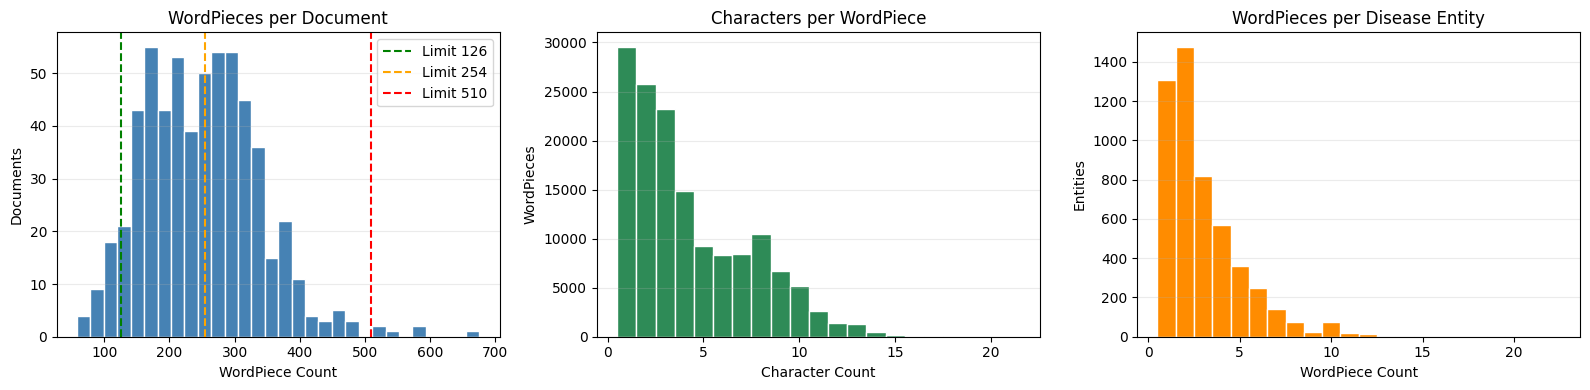

In [10]:
# Load the PubMedBERT-tokenized training records.
with pubmedbert_training_path.open(encoding="utf-8") as source:
    pubmedbert_records = [
        json.loads(line) for line in source if line.strip()
    ]

pubmedbert_document_token_counts = [
    len(record["tokens"]) for record in pubmedbert_records
]
pubmedbert_token_character_lengths = [
    offset["end"] - offset["start"]
    for record in pubmedbert_records
    for offset in record["offset_mapping"]
]
pubmedbert_entity_wordpiece_counts = []
pubmedbert_boundary_aligned_entities = 0

for record in pubmedbert_records:
    offsets = record["offset_mapping"]
    token_starts = {offset["start"] for offset in offsets}
    token_ends = {offset["end"] for offset in offsets}

    for entity in record["entities"]:
        wordpiece_count = sum(
            offset["start"] < entity["end"]
            and offset["end"] > entity["start"]
            for offset in offsets
        )
        pubmedbert_entity_wordpiece_counts.append(wordpiece_count)

        is_boundary_aligned = (
            entity["start"] in token_starts
            and entity["end"] in token_ends
        )
        pubmedbert_boundary_aligned_entities += int(
            is_boundary_aligned
        )


def describe_pubmedbert_values(name, values):
    values = pd.Series(values)
    return {
        "Measurement": name,
        "Count": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Minimum": values.min(),
        "95th Percentile": values.quantile(0.95),
        "Maximum": values.max(),
    }


pubmedbert_token_statistics = pd.DataFrame([
    describe_pubmedbert_values(
        "WordPieces per document",
        pubmedbert_document_token_counts,
    ),
    describe_pubmedbert_values(
        "Characters per WordPiece",
        pubmedbert_token_character_lengths,
    ),
    describe_pubmedbert_values(
        "WordPieces per entity",
        pubmedbert_entity_wordpiece_counts,
    ),
]).set_index("Measurement")
display(pubmedbert_token_statistics.round(2))

pubmedbert_capacity_rows = []
for model_max_length in (128, 256, 512):
    content_limit = model_max_length - 2
    exceeding_count = sum(
        count > content_limit
        for count in pubmedbert_document_token_counts
    )
    pubmedbert_capacity_rows.append({
        "Model Max Length": model_max_length,
        "Content WordPiece Limit": content_limit,
        "Documents Exceeding Limit": exceeding_count,
        "Documents Exceeding Limit (%)": (
            exceeding_count
            / len(pubmedbert_document_token_counts)
            * 100
        ),
    })

pubmedbert_capacity_summary = pd.DataFrame(
    pubmedbert_capacity_rows
).set_index("Model Max Length")
display(pubmedbert_capacity_summary.round(2))

pubmedbert_total_entities = len(
    pubmedbert_entity_wordpiece_counts
)
pubmedbert_single_wordpiece_entities = sum(
    count == 1 for count in pubmedbert_entity_wordpiece_counts
)
pubmedbert_entity_alignment_summary = pd.DataFrame({
    "Metric": [
        "Single-WordPiece entities",
        "Multi-WordPiece entities",
        "Boundary-aligned entities",
        "Boundary-unaligned entities",
    ],
    "Count": [
        pubmedbert_single_wordpiece_entities,
        pubmedbert_total_entities
        - pubmedbert_single_wordpiece_entities,
        pubmedbert_boundary_aligned_entities,
        pubmedbert_total_entities
        - pubmedbert_boundary_aligned_entities,
    ],
}).set_index("Metric")
pubmedbert_entity_alignment_summary["Percentage"] = (
    pubmedbert_entity_alignment_summary["Count"]
    / pubmedbert_total_entities
    * 100
)
display(pubmedbert_entity_alignment_summary.round(2))

# Plot the PubMedBERT tokenization distributions.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(
    pubmedbert_document_token_counts,
    bins=30,
    color="steelblue",
    edgecolor="white",
)
for limit, color in zip((126, 254, 510), ("green", "orange", "red")):
    axes[0].axvline(
        limit,
        color=color,
        linestyle="--",
        label=f"Limit {limit}",
    )
axes[0].set_title("WordPieces per Document")
axes[0].set_xlabel("WordPiece Count")
axes[0].set_ylabel("Documents")
axes[0].legend()

pubmedbert_token_length_bins = np.arange(
    0.5, max(pubmedbert_token_character_lengths) + 1.5, 1
)
axes[1].hist(
    pubmedbert_token_character_lengths,
    bins=pubmedbert_token_length_bins,
    color="seagreen",
    edgecolor="white",
)
axes[1].set_title("Characters per WordPiece")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("WordPieces")

pubmedbert_entity_piece_bins = np.arange(
    0.5, max(pubmedbert_entity_wordpiece_counts) + 1.5, 1
)
axes[2].hist(
    pubmedbert_entity_wordpiece_counts,
    bins=pubmedbert_entity_piece_bins,
    color="darkorange",
    edgecolor="white",
)
axes[2].set_title("WordPieces per Disease Entity")
axes[2].set_xlabel("WordPiece Count")
axes[2].set_ylabel("Entities")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()